# Machine Learning Final Project: 
## Neuro-Symbolic Differentiable Rule Extractor (NSDRE)

**Creator**: Iman Sharifi, G46454668

In [1]:
import numpy as np

def interpret_neuron_weights_(pred_values, Weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    

    interpretations = []
    for i, weights in enumerate(Weights):

        # Find predicate value of a given neuron
        pred_value = pred_values[i]

        # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')
    return interpretations

import numpy as np

def interpret_neuron_weights(Weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    

    interpretations = []
    for i, weights in enumerate(Weights):

        # compute {weights[0], weights[1], weights[2]}
        new_weights = [weights[0], weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')
    return interpretations

In [3]:
import torch
def compute_acc_ratio_all_rules_attention(model, x, y, beta=10.0):
    with torch.no_grad():
        rule_outputs = []
        for rule in model.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % model.input_dim]]
                conjunctions.append(neuron(xi).squeeze())
            # Softmin attention over neurons (optional, or just use sum)
            conjunctions = torch.stack(conjunctions, dim=1)  # (batch, num_neurons)
            attention_weights = torch.softmax(-beta * conjunctions, dim=1)
            outputs = (attention_weights * conjunctions).sum(dim=1)  # (batch,)
            activated_outputs = torch.sigmoid(5 * (outputs - 0.5))
            rule_outputs.append(activated_outputs)

        # Stack rule outputs: shape (num_rules, batch)
        rule_outputs_tensor = torch.stack(rule_outputs, dim=0)  # (num_rules, batch)
        # Softmax attention over rules for each sample (dim=0)
        attention_weights = torch.softmax(beta * rule_outputs_tensor, dim=0)
        # Weighted sum over rules for each sample
        final_output = (attention_weights * rule_outputs_tensor).sum(dim=0)  # (batch,)
        # Compute accuracy
        preds = (final_output > 0.5).float()
        acc = (preds == (y > 0.5)).float().mean().item()
        return acc

## Learning desire rules from posivitive and negative examples and boolean inputs

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        # weights = torch.sigmoid(self.raw_weights)
        weights = torch.softmax(self.raw_weights, dim=0)  # Normalize weights to sum to 1

        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]
            outputs.append(neuron(xi))
        # Soft min of neuron outputs using attention mechanism
        # find -beta * outputs for all neurons, where beta is a hyperparameter
        beta = 10.0  # Example value for beta
        attention_weights = torch.softmax(-beta * torch.stack(outputs), dim=0)
        outputs = [attention_weights[i] * outputs[i] for i in range(self.num_neurons)]
        activated_outputs = torch.sigmoid(5*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
        return activated_outputs

In [5]:
# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        # weights = torch.sigmoid(self.raw_weights)
        weights = torch.softmax(self.raw_weights, dim=0)  # Normalize weights to sum to 1

        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        outputs = []
        Sum_third_weights = 0
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]
            outputs.append(neuron(xi))
            with torch.no_grad():
                Sum_third_weights += torch.softmax(neuron.raw_weights, dim=0)[2]
        rule_output = torch.exp(sum(outputs))  # Sum of neuron outputs
        Sum_third_weights = max(Sum_third_weights.detach(), 1)  # Turn off the gradient for Sum_third_weights
        activated_outputs = torch.sigmoid(5*(rule_output - 0.5))  # Apply sigmoid to the sum
        return activated_outputs

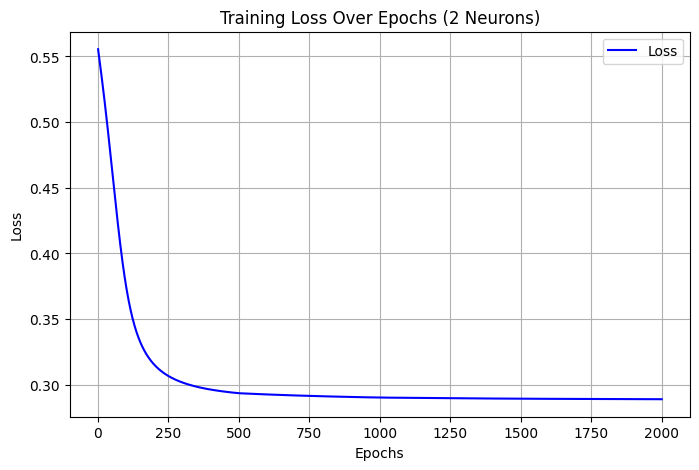


Final Weights of the Network:
Neuron 1: [0.9951874017715454, 0.003436482045799494, 0.0013760479632765055]
Neuron 2: [0.002800782909616828, 0.9955586194992065, 0.001640628557652235]

Extracted Rule:
h :- b1 and not(b2).


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import random
from collections import Counter

# Stabilize reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Settings
num_neurons = 2
input_dim = num_neurons
num_samples = 1000

# Synthetic Data
X_train = torch.rand(num_samples, input_dim)

# Bitwise operations for labels
y_train = ((X_train[:, 0] > 0.5) & ((1-X_train[:, 1]) > 0.5)).float()  # h :- b1 and not b2

# Model setup
model_nsre = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
# criterion = nn.BCEWithLogitsLoss()
criterion = nn.BCELoss()  # Use BCELoss for binary classification
optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

# Training Loop
num_epochs = 2000
losses_nsre = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = model_nsre(X_train).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    losses_nsre.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Output final weights
Weights_nsre = []
for i, neuron in enumerate(model_nsre.neurons):
    weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()

    Weights_nsre.append(weights)

print("\nFinal Weights of the Network:")
for i, weights in enumerate(Weights_nsre):
    print(f"Neuron {i+1}: {weights}")

preds = interpret_neuron_weights(Weights_nsre)  # Pass pred_values and Weights_nsre
refined_preds = [pred for pred in preds if pred != '1']  # Filter out '1'
rule = f"h :- " + " and ".join(refined_preds) + "."
print("\nExtracted Rule:")
print(rule)

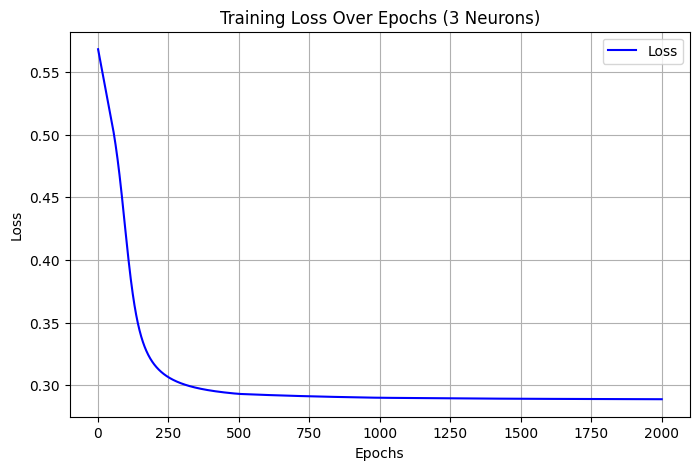

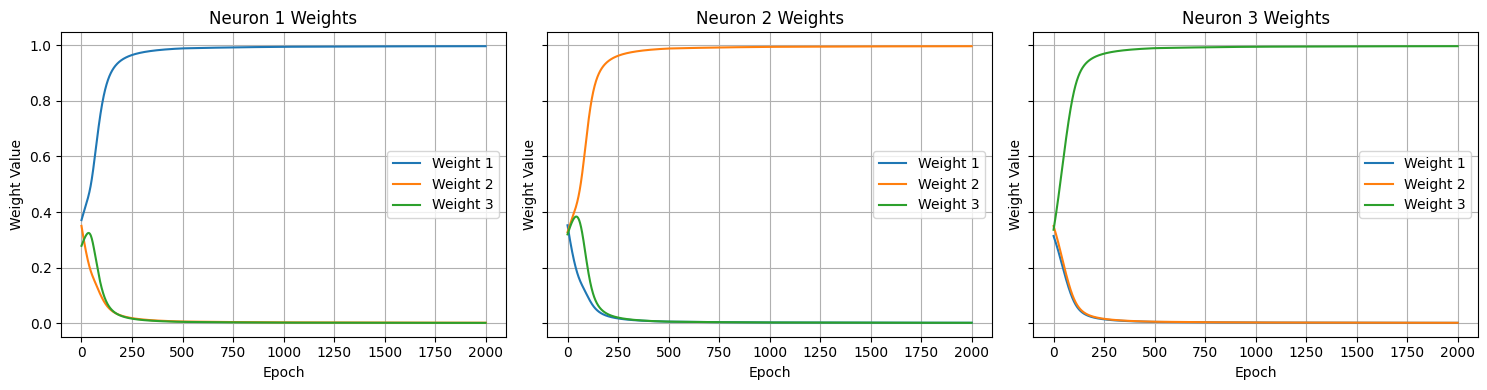

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import random
from collections import Counter

# Stabilize reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Settings
num_neurons = 3
input_dim = num_neurons
num_samples = 1000

# Synthetic Data
X_train = torch.rand(num_samples, input_dim)

# Bitwise operations for labels
y_train = ((X_train[:, 0] > 0.5) & ((1-X_train[:, 1]) > 0.5)).float()  # h :- b1 and not b2

# Model setup
model_nsre = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
# criterion = nn.BCEWithLogitsLoss()
criterion = nn.BCELoss()  # Use BCELoss for binary classification
optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

# Training Loop
num_epochs = 2000
losses_nsre = []

weights_history = [[] for _ in range(num_neurons)]  # List of lists for each neuron

for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = model_nsre(X_train).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    losses_nsre.append(loss.item())
    # Save softmax weights for each neuron
    for i, neuron in enumerate(model_nsre.neurons):
        w = torch.softmax(neuron.raw_weights, dim=0).detach().cpu().numpy()
        weights_history[i].append(w)

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre[-num_epochs:], label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, num_neurons, figsize=(5 * num_neurons, 4), sharey=True)
if num_neurons == 1:
    axes = [axes]
for i in range(num_neurons):
    weights_arr = np.array(weights_history[i])  # shape: (epochs, 3)
    for j in range(weights_arr.shape[1]):
        axes[i].plot(weights_arr[:, j], label=f'Weight {j+1}', )
    axes[i].set_title(f'Neuron {i+1} Weights')
    axes[i].set_xlabel('Epoch')
    axes[i].set_ylabel('Weight Value')
    axes[i].legend()
    axes[i].grid(True)
plt.tight_layout()
plt.show()

## Learning More than one rule using NSDRE

## Example rule: 

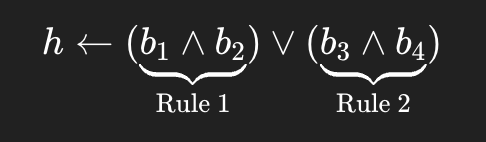

### $h \leftarrow h_1 \vee h_2$

### $h_1 \leftarrow b_1 \wedge b_2$

### $h_2 \leftarrow b_3 \wedge b_4$

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(5*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(5*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

        return activated_output

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(activated_input)

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            Sum_third_weights = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                with torch.no_grad():
                    Sum_third_weights += weights[2]
            Sum_third_weights = Sum_third_weights.detach()
            Sum_third_weights = max(Sum_third_weights, 1)
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            rule_output = torch.exp(sum(conjunctions))
            activated_rule_output = torch.sigmoid(5 * (rule_output - 1 / 2**(self.input_dim - Sum_third_weights)))
            rule_outputs.append(activated_rule_output)

        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r

        return fuzzy_or

## The most stable version of the code:

1 - Added Multiple Initial values

2 - Added entropy for weight exploration 

## Learning More than one rule using NSDRE

## Example rule: 

### $h \leftarrow h_1 \vee h_2$

- $h_1 \leftarrow b_1 \wedge \neg b_2$

- $h_2 \leftarrow b_3 \wedge b_4$

Restart 1/1 Final Loss: 0.6931


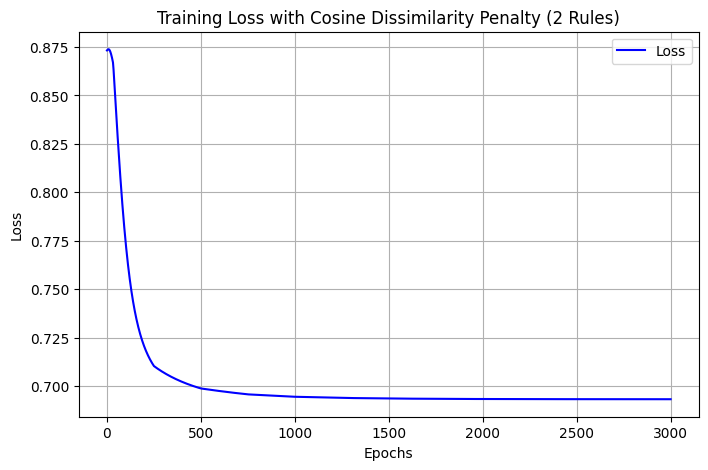


Final Weights of the Network:
Rule 1:
  Neuron 1: [0.9884251356124878, 0.003494296222925186, 0.008080518804490566]
  Neuron 2: [0.0037492006085813046, 0.9893110990524292, 0.00693972734734416]
  Neuron 3: [0.9896976351737976, 0.0033467260655015707, 0.006955553777515888]
  Neuron 4: [0.9890673756599426, 0.004212907049804926, 0.006719736848026514]
Rule 2:
  Neuron 1: [0.989113450050354, 0.0035809651017189026, 0.007305579259991646]
  Neuron 2: [0.004083073697984219, 0.9893038272857666, 0.006612996570765972]
  Neuron 3: [0.9888494610786438, 0.003485644469037652, 0.007664963603019714]
  Neuron 4: [0.9884445667266846, 0.0038332478143274784, 0.007722079753875732]
The most repeated rule is: 'h1 :- b1 and not(b2) and b3 and b4.'
Accuracy over training data: 0.98.
The most repeated rule is: 'h2 :- b1 and not(b2) and b3 and b4.'
Accuracy over training data: 0.979.

Final Rule:
h :- b1 and not(b2) and b3 and b4 OR b1 and not(b2) and b3 and b4.


In [12]:
from collections import Counter
# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = num_neurons_per_rule
num_samples = 1000
num_epochs = 3000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
# Binary input data
# X_train = (torch.rand(num_samples, input_dim) > 0.5).float()

# Probability input data
X_train = torch.rand(num_samples, input_dim)  # Random probabilities
# X_train = torch.distributions.Beta(0.3, 0.3).sample((num_samples, input_dim))  # Random features from Beta distribution

# X_train[X_train == 0] = 0.1 * torch.rand(X_train[X_train == 0].shape)  # Replace 0 with a small value to avoid log(0)
# y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()
y_train = (((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))|((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5))).float()
# y_train = ((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5)).float()
# y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()  # Use BCELoss for binary classification
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=250, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        # Cosine similarity loss
        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Entropy regularization for exploration
        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + entropy_weight * entropy_term #+ similarity_weight * penalty #+ entropy_weight * entropy_term
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load the best model
best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal Weights of the Network:")
for rule_num, rule_weights in enumerate(Weights_nsre):
    print(f"Rule {rule_num+1}:")
    for i, weights in enumerate(rule_weights):
        print(f"  Neuron {i+1}: {weights}") 

# Rule interpretation
Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


## Plot weights

Restart 1/1 Final Loss: 0.3496


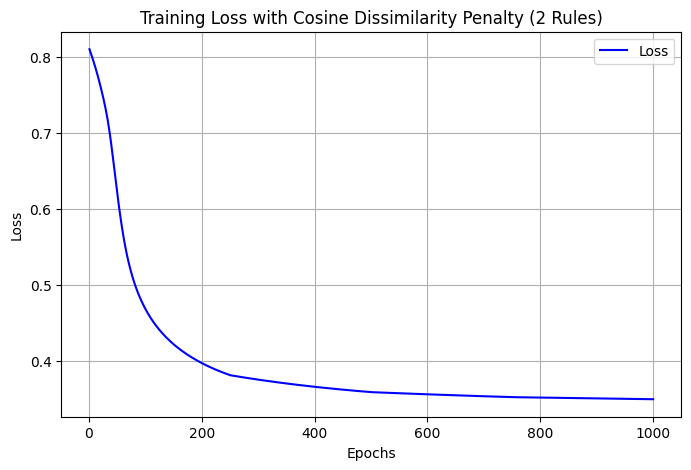

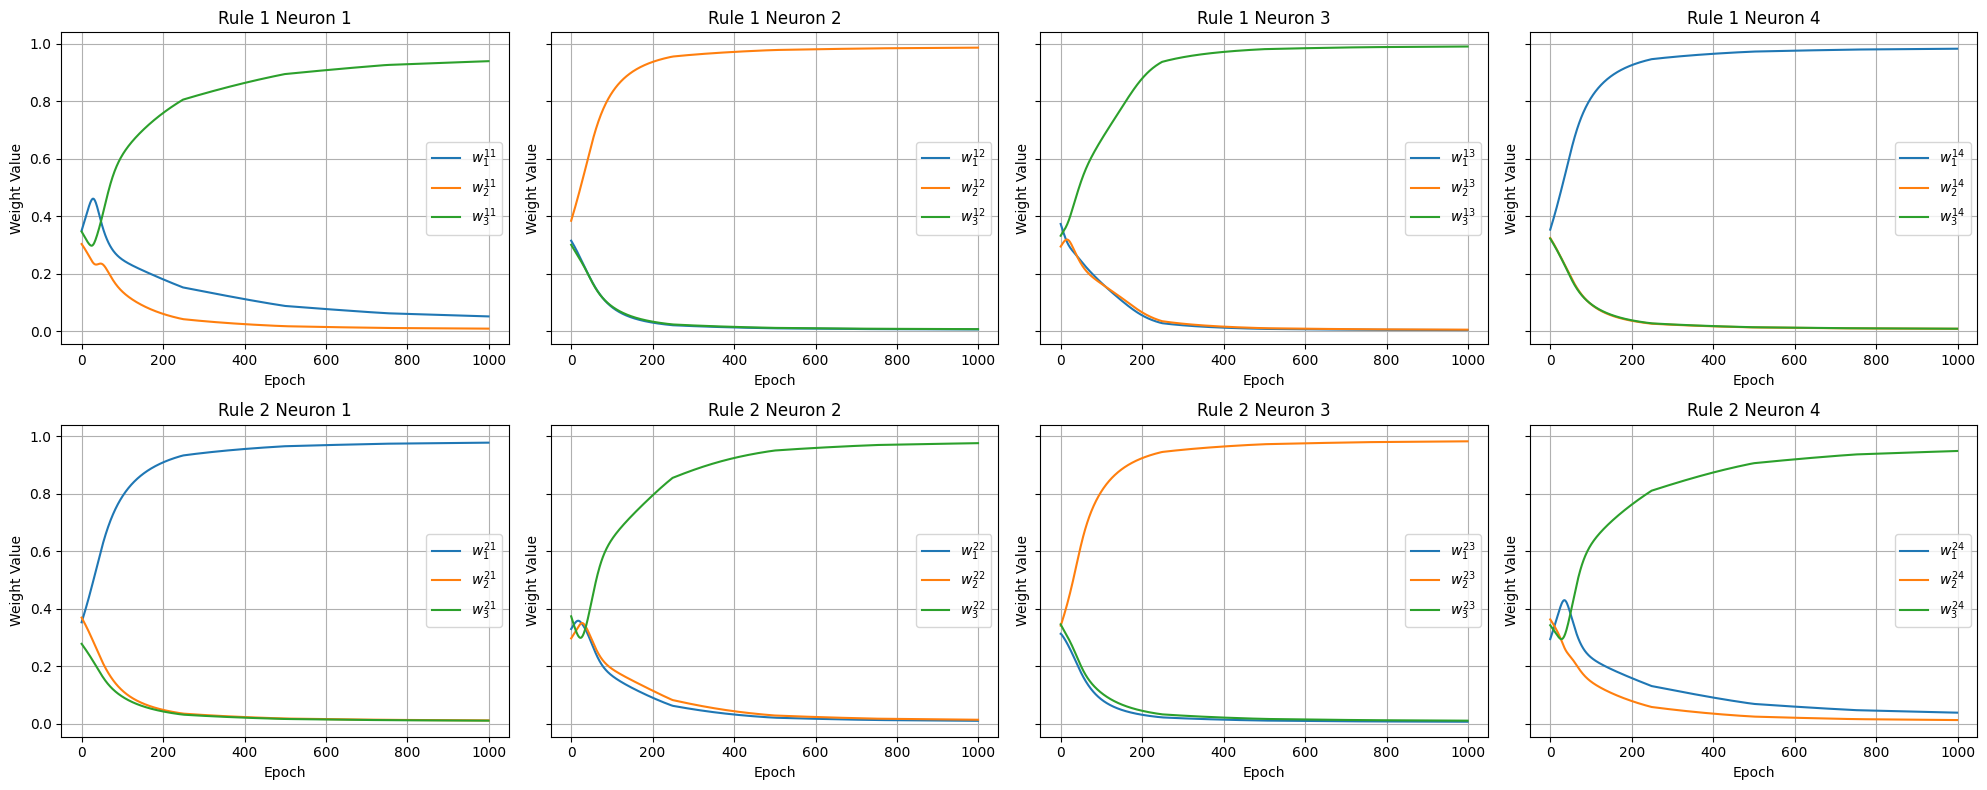


Final Weights of the Network:
Rule 1:
  Neuron 1: [0.05169080197811127, 0.009158254601061344, 0.9391509294509888]
  Neuron 2: [0.006393875926733017, 0.986174464225769, 0.007431636098772287]
  Neuron 3: [0.004275386221706867, 0.005575916264206171, 0.990148663520813]
  Neuron 4: [0.9824571013450623, 0.008588200435042381, 0.008954774588346481]
Rule 2:
  Neuron 1: [0.9774695038795471, 0.011732116341590881, 0.010798370465636253]
  Neuron 2: [0.010277984663844109, 0.01399532426148653, 0.9757266640663147]
  Neuron 3: [0.007064293138682842, 0.9821213483810425, 0.010814405977725983]
  Neuron 4: [0.03863397240638733, 0.012902564369142056, 0.9484634399414062]
The most repeated rule is: 'h1 :- not(b2) and b4.'
Accuracy over training data: 0.96.
The most repeated rule is: 'h2 :- b1 and not(b3).'
Accuracy over training data: 0.98.

Final Rule:
h :- not(b2) and b4 OR b1 and not(b3).
Execution time: 1.91 seconds


In [6]:
from collections import Counter
import time
start_time = time.time()
# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = num_neurons_per_rule
num_samples = 100
num_epochs = 1000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
# Binary input data
# X_train = (torch.rand(num_samples, input_dim) > 0.5).float()

# Probability input data
X_train = torch.rand(num_samples, input_dim)  # Random probabilities
# X_train = torch.distributions.Beta(0.3, 0.3).sample((num_samples, input_dim))  # Random features from Beta distribution

# X_train[X_train == 0] = 0.1 * torch.rand(X_train[X_train == 0].shape)  # Replace 0 with a small value to avoid log(0)
# y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()
y_train = ((((1 - X_train[:, 1]) > 0.5) & (X_train[:, 3] > 0.5))|((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5))).float()
# y_train = ((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5)).float()
# y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

# Initialize history for weights: [rule][neuron][epoch][weight]
weights_history = [
    [ [] for _ in range(num_neurons_per_rule) ]
    for _ in range(num_rules)
]

for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()  # Use BCELoss for binary classification
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=250, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        # Cosine similarity loss
        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Entropy regularization for exploration
        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + entropy_weight * entropy_term #+ similarity_weight * penalty
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

        # Save weights for each neuron in each rule
        for rule_idx, rule in enumerate(model_nsre.rules):
            for neuron_idx, neuron in enumerate(rule):
                w = torch.softmax(neuron.raw_weights, dim=0).detach().cpu().numpy()
                weights_history[rule_idx][neuron_idx].append(w)

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load the best model
best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Plot weights for each neuron in each rule
fig, axes = plt.subplots(num_rules, num_neurons_per_rule, figsize=(5 * num_neurons_per_rule, 4 * num_rules), sharey=True)
if num_rules == 1:
    axes = [axes]
for rule_idx in range(num_rules):
    for neuron_idx in range(num_neurons_per_rule):
        ax = axes[rule_idx][neuron_idx] if num_rules > 1 else axes[neuron_idx]
        weights_arr = np.array(weights_history[rule_idx][neuron_idx])  # shape: (epochs, 3)
        for w_idx in range(weights_arr.shape[1]):
            label = f'$w_{w_idx+1}^{{{rule_idx+1}{neuron_idx+1}}}$'
            ax.plot(weights_arr[:, w_idx], label=label)
        ax.set_title(f'Rule {rule_idx+1} Neuron {neuron_idx+1}')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Weight Value')
        ax.legend()
        ax.grid(True)
plt.tight_layout()
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal Weights of the Network:")
for rule_num, rule_weights in enumerate(Weights_nsre):
    print(f"Rule {rule_num+1}:")
    for i, weights in enumerate(rule_weights):
        print(f"  Neuron {i+1}: {weights}") 

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")

end_time = time.time()
execution_time = end_time - start_time
print(f"Execution time: {execution_time:.2f} seconds")


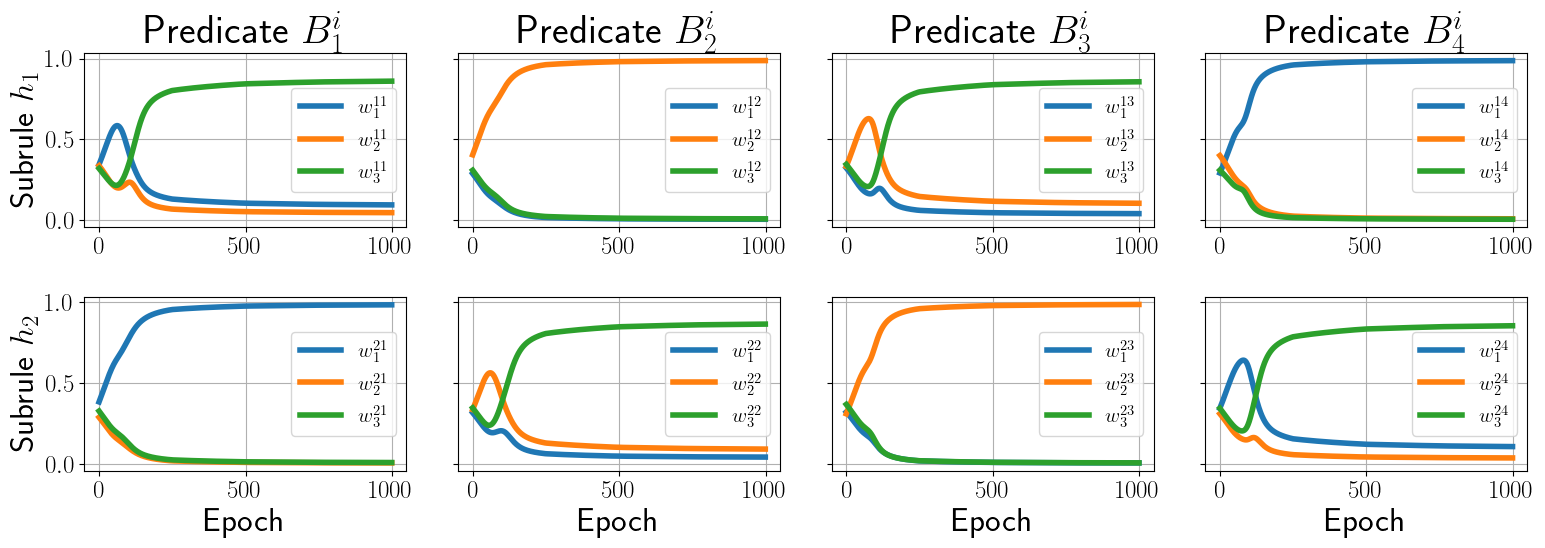

In [40]:
plt.rcParams.update({'font.size': 24, 'text.usetex': True})  # Set global font size
fig, axes = plt.subplots(num_rules, num_neurons_per_rule, figsize=(4 * num_neurons_per_rule, 3 * num_rules), sharey=True)
if num_rules == 1:
    axes = [axes]
for rule_idx in range(num_rules):
    for neuron_idx in range(num_neurons_per_rule):
        ax = axes[rule_idx][neuron_idx] if num_rules > 1 else axes[neuron_idx]
        weights_arr = np.array(weights_history[rule_idx][neuron_idx])  # shape: (epochs, 3)
        for w_idx in range(weights_arr.shape[1]):
            label = f'$w_{w_idx+1}^{{{rule_idx+1}{neuron_idx+1}}}$'
            ax.plot(weights_arr[:, w_idx], label=label, linewidth=4)
        if rule_idx == 0:
            ax.set_title(f'Predicate $B_{neuron_idx+1}^i$')
        if rule_idx == num_rules - 1:
            ax.set_xlabel('Epoch')
        if neuron_idx == 0:
            ax.set_ylabel(f'Subrule $h_{rule_idx+1}$')
        ax.legend(loc='center right', fontsize=15)
        ax.grid(True)
        ax.tick_params(axis='both', labelsize=18)

plt.tight_layout()
plt.savefig('weights_plot.pdf', bbox_inches='tight')
plt.show()

## Adding Curriculum Learning

### Two subrules

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

# Define CustomNeuron and FuzzyDisjunctionNet (assumed already defined in the user environment)

# Curriculum Learning Configuration
Num_rules = 2  # Number of rules to learn step-by-step
num_neurons_per_rule = 4
input_dim = num_neurons_per_rule
num_samples = 500
num_epochs = 1000
num_restarts = 3
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = ((((1 - X_train[:, 1]) > 0.5) & (X_train[:, 3] > 0.5))|((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5))).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Function to freeze a rule
def freeze_rule(model, rule_index):
    for param in model.rules[rule_index].parameters():
        param.requires_grad = False

# Store best model at each stage
frozen_rule_states = []

# Initialize history for weights: [rule][neuron][epoch][weight]
weights_history = [
    [ [] for _ in range(num_neurons_per_rule) ]
    for _ in range(Num_rules)
]
best_losses_lst = []
best_acc_lst = []

# Curriculum Learning Loop
for rule_index in range(Num_rules):  # Learn 3 rules step-by-step
    print(f"\n=== Training Rule {rule_index + 1} ===")

    num_rules = rule_index + 1
    best_state_dict = None
    best_loss = float('inf')
    best_losses = []
    best_accs = []

    for restart in range(num_restarts):
        model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)

        # Load and freeze previous rules
        if frozen_rule_states:
            print("***")
            model_nsre.load_state_dict(frozen_rule_states[-1], strict=False)
            for i in range(rule_index):
                freeze_rule(model_nsre, i)

        criterion = nn.BCELoss()
        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model_nsre.parameters()), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=250, gamma=0.5)

        losses_nsre = []
        accs_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            entropy_term = sum(model_nsre.entropies)
            total_loss = bce_loss - entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

            # Save weights for each neuron in each rule
            if num_rules == Num_rules:
                for rule_idx, rule in enumerate(model_nsre.rules):
                    for neuron_idx, neuron in enumerate(rule):
                        w = torch.softmax(neuron.raw_weights, dim=0).detach().cpu().numpy()
                        weights_history[rule_idx][neuron_idx].append(w)

            acc_nsre = compute_acc_ratio_all_rules_attention(model_nsre, X_train, y_train)
            accs_nsre.append(acc_nsre)

        final_loss = losses_nsre[-1]
        print(f"Restart {restart + 1}/{num_restarts}, Final Loss: {final_loss:.4f}")
        if final_loss < best_loss:
            best_loss = final_loss
            best_losses = losses_nsre
            best_accs = accs_nsre
            best_state_dict = deepcopy(model_nsre.state_dict())
    
        # # Load final model
        # final_model = FuzzyDisjunctionNet(Num_rules, num_neurons_per_rule, input_dim)
        # final_model.load_state_dict(frozen_rule_states[-1], strict=False)

        # Save final weights
        Weights_nsre = []
        for rule in model_nsre.rules:
            rule_weights = []
            for neuron in rule:
                weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
                rule_weights.append(weights)
            Weights_nsre.append(rule_weights)

        # Rule interpretation
        Predicate_values = X_train

        Final_rules = []
        for rule_num, weights in enumerate(Weights_nsre):
            Extracted_rules = []
            for i in range(len(Predicate_values)):
                pred_values = Predicate_values[i].numpy()
                preds = interpret_neuron_weights_(pred_values, weights)
                refined_preds = [pred for pred in preds if pred != '1']
                rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
                Extracted_rules.append(rule)

            rule_counts = Counter(Extracted_rules)
            most_common_rule, count = rule_counts.most_common(1)[0]
            print(f"The most repeated rule is: '{most_common_rule}'")
            print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

            Final_rules.append(most_common_rule)

    best_losses_lst.append(best_losses)
    best_acc_lst.append(best_accs)
    frozen_rule_states.append(best_state_dict)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


=== Training Rule 1 ===
Restart 1/3, Final Loss: 0.4897
The most repeated rule is: 'h1 :- b1 and not(b3).'
Accuracy over training data: 0.744.
Restart 2/3, Final Loss: 0.4975
The most repeated rule is: 'h1 :- not(b2) and b4.'
Accuracy over training data: 0.834.
Restart 3/3, Final Loss: 0.5546
The most repeated rule is: 'h1 :- b1 and b4.'
Accuracy over training data: 0.46.

=== Training Rule 2 ===
***
Restart 1/3, Final Loss: 0.3224
The most repeated rule is: 'h1 :- b1 and not(b3).'
Accuracy over training data: 0.744.
The most repeated rule is: 'h2 :- not(b2) and b4.'
Accuracy over training data: 0.956.
***
Restart 2/3, Final Loss: 0.3228
The most repeated rule is: 'h1 :- b1 and not(b3).'
Accuracy over training data: 0.744.
The most repeated rule is: 'h2 :- not(b2) and b4.'
Accuracy over training data: 0.956.
***
Restart 3/3, Final Loss: 0.3228
The most repeated rule is: 'h1 :- b1 and not(b3).'
Accuracy over training data: 0.744.
The most repeated rule is: 'h2 :- not(b2) and b4.'
Accur

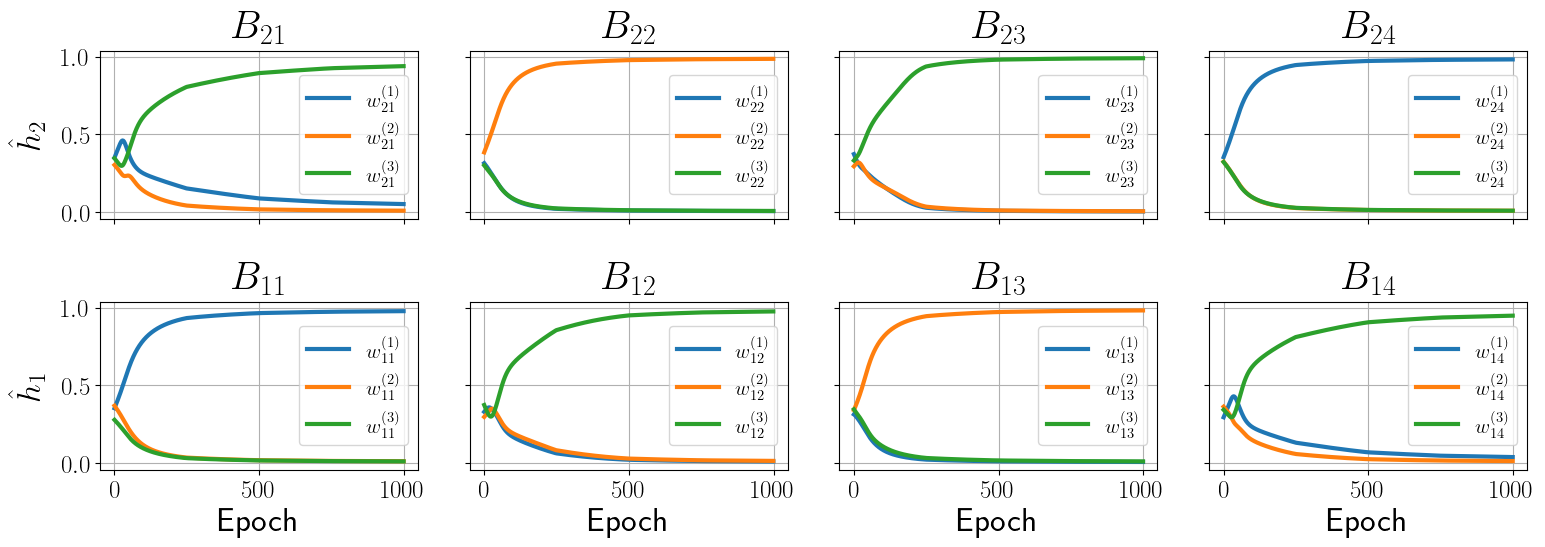

In [14]:
plt.rcParams.update({'font.size': 24, 'text.usetex': True})  # Set global font size
fig, axes = plt.subplots(num_rules, num_neurons_per_rule, figsize=(4 * num_neurons_per_rule, 3 * num_rules), sharey=True)
if num_rules == 1:
    axes = [axes]
for rule_idx in range(num_rules):
    for neuron_idx in range(num_neurons_per_rule):
        ax = axes[rule_idx][neuron_idx] if num_rules > 1 else axes[neuron_idx]
        weights_arr = np.array(weights_history[rule_idx][neuron_idx])  # shape: (epochs, 3)
        for w_idx in range(weights_arr.shape[1]):
            if rule_idx == 0:
                label = f'$w_{{{rule_idx+2}{neuron_idx+1}}}^{{({w_idx+1})}}$'
            else:
                label = f'$w_{{{rule_idx}{neuron_idx+1}}}^{{({w_idx+1})}}$'
            ax.plot(weights_arr[:, w_idx], label=label, linewidth=3)
        if rule_idx == 0:
            x = 20+neuron_idx+1
            ax.set_title(f'$B_{{{x}}}$', pad=10)
        else:
            x = 10+neuron_idx+1
            ax.set_title(f'$B_{{{x}}}$', pad=10)
        if rule_idx == num_rules - 1:
            ax.set_xlabel('Epoch')
        if neuron_idx == 0:
            if rule_idx == 0:
                ax.set_ylabel(f'$\\hat{{h}}_2$', labelpad=10)
            else:
                ax.set_ylabel(f'$\\hat{{h}}_1$', labelpad=10)
        ax.legend(loc='center right', fontsize=15)
        ax.grid(True)
        ax.tick_params(axis='both', labelsize=18)
        # set off xtick labels for all but the last row
        if rule_idx != num_rules - 1:
            ax.set_xticklabels([])

plt.tight_layout()
plt.savefig('weights_plot.pdf', bbox_inches='tight')
plt.show()

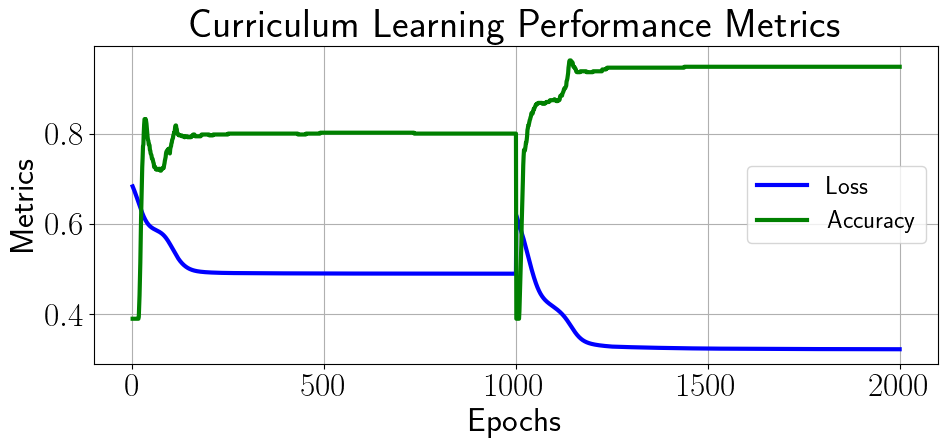

In [12]:
final_losses = best_losses_lst[0] + best_losses_lst[1]
final_accuracys = best_acc_lst[0] + best_acc_lst[1]
# plot the final losses
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(final_losses) + 1), final_losses, label="Loss", color="Blue", linewidth=3)
plt.plot(range(1, len(final_accuracys) + 1), final_accuracys, label="Accuracy", color="green", linewidth=3)
plt.xlabel("Epochs")
plt.ylabel("Metrics")
plt.legend(loc='center right', fontsize=18)
plt.grid(True)
plt.title(f"Curriculum Learning Performance Metrics") 
plt.tight_layout()
plt.savefig('curriculum_learning_performance.pdf', bbox_inches='tight')

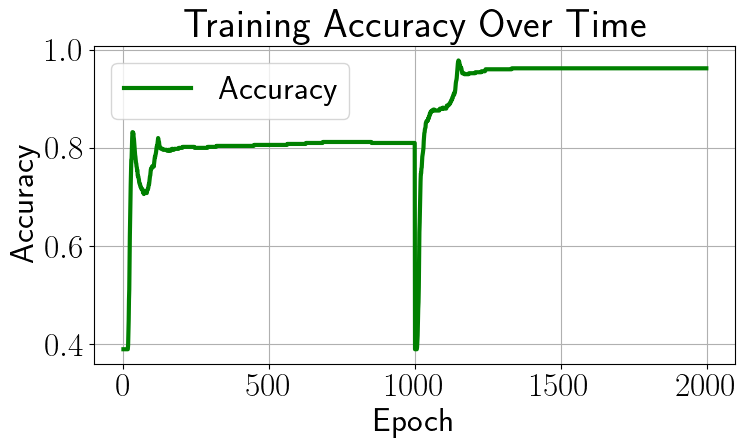

In [59]:
# plot the accuracy
accuracys = best_acc_lst[0] + best_acc_lst[1]
plt.figure(figsize=(8, 5))
plt.plot(accuracys, label='Accuracy', color='green', linewidth=3)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training Accuracy Over Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Three subrules

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

# Define CustomNeuron and FuzzyDisjunctionNet (assumed already defined in the user environment)

# Curriculum Learning Configuration
Num_rules = 3  # Number of rules to learn step-by-step
num_neurons_per_rule = 6
input_dim = num_neurons_per_rule
num_samples = 3000
num_epochs = 2000
num_restarts = 3
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
# torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5)) | 
           (((1 - X_train[:, 4]) > 0.5) & (X_train[:, 5] > 0.5))).float()
# y_train = ((X_train[:, 0] * (1 - X_train[:, 1]) > 0.25) | ((X_train[:, 2] * X_train[:, 3]) > 0.25)).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Function to freeze a rule
def freeze_rule(model, rule_index):
    for param in model.rules[rule_index].parameters():
        param.requires_grad = False

# Store best model at each stage
frozen_rule_states = []
best_loss_for_save = []
best_acc_for_save = []

# Curriculum Learning Loop
for rule_index in range(Num_rules):  # Learn 3 rules step-by-step
    print(f"\n=== Training Rule {rule_index + 1} ===")

    num_rules = rule_index + 1
    best_state_dict = None
    best_loss = float('inf')
    best_losses = []

    for restart in range(num_restarts):
        model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)

        # Load and freeze previous rules
        if frozen_rule_states:
            print("***")
            model_nsre.load_state_dict(frozen_rule_states[-1], strict=False)
            for i in range(rule_index):
                freeze_rule(model_nsre, i)

        criterion = nn.BCELoss()
        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model_nsre.parameters()), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=250, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            entropy_term = sum(model_nsre.entropies)
            total_loss = bce_loss #+ similarity_weight * penalty - entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Restart {restart + 1}/{num_restarts}, Final Loss: {final_loss:.4f}")
        if final_loss < best_loss:
            best_loss = final_loss
            best_losses = losses_nsre
            best_state_dict = deepcopy(model_nsre.state_dict())
    

        # # Load final model
        # final_model = FuzzyDisjunctionNet(Num_rules, num_neurons_per_rule, input_dim)
        # final_model.load_state_dict(frozen_rule_states[-1], strict=False)

        # Save final weights
        Weights_nsre = []
        for rule in model_nsre.rules:
            rule_weights = []
            for neuron in rule:
                weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
                rule_weights.append(weights)
            Weights_nsre.append(rule_weights)

        # Rule interpretation
        Predicate_values = X_train

        Final_rules = []
        for rule_num, weights in enumerate(Weights_nsre):
            Extracted_rules = []
            for i in range(len(Predicate_values)):
                pred_values = Predicate_values[i].numpy()
                preds = interpret_neuron_weights_(pred_values, weights)
                refined_preds = [pred for pred in preds if pred != '1']
                rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
                Extracted_rules.append(rule)

            rule_counts = Counter(Extracted_rules)
            most_common_rule, count = rule_counts.most_common(1)[0]
            print(f"The most repeated rule is: '{most_common_rule}'")
            print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

            Final_rules.append(most_common_rule)

    frozen_rule_states.append(best_state_dict)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


=== Training Rule 1 ===
Restart 1/3, Final Loss: 0.6021
The most repeated rule is: 'h1 :- b1.'
Accuracy over training data: 0.31533333333333335.
Restart 2/3, Final Loss: 0.6022
The most repeated rule is: 'h1 :- b1.'
Accuracy over training data: 0.31666666666666665.
Restart 3/3, Final Loss: 0.5940
The most repeated rule is: 'h1 :- not(b5) and b6.'
Accuracy over training data: 0.266.

=== Training Rule 2 ===
***
Restart 1/3, Final Loss: 0.5020
The most repeated rule is: 'h1 :- not(b5) and b6.'
Accuracy over training data: 0.266.
The most repeated rule is: 'h2 :- b1 and not(b2).'
Accuracy over training data: 0.978.
***
Restart 2/3, Final Loss: 0.5019
The most repeated rule is: 'h1 :- not(b5) and b6.'
Accuracy over training data: 0.266.
The most repeated rule is: 'h2 :- b1 and not(b2).'
Accuracy over training data: 0.9766666666666667.
***
Restart 3/3, Final Loss: 0.5018
The most repeated rule is: 'h1 :- not(b5) and b6.'
Accuracy over training data: 0.266.
The most repeated rule is: 'h2 :-

## Learning Structured Rules

Given this set of potential predicates $\{b_1(X_1, X_2), b_2(X_1), b_3(X_2, X_3), b_4(X_1, X_3)\}$ and the binary values for the head predicate $h(X_1, X_3)$, we aim to find the following target rule:

$h(X_1, X_3) :- b_1(X_1, X_2) \wedge \neg b_3(X_2, X_3)$,

where head variables are $X_1$ and $X_3$, and $X_2$ is an auxiliary variable. Each rule should satisfy these two conditions:

- Head variables should be present in the body of the rule.

- Auxiliary variables either should not be available in the body of the rule or should be available at least twice.

To enforce such conditions, we consider the following vector embeddings:

$X = [X_m]_{j=1}^m$, where $x_j$ is the probability of the existense of variable $X_j$ in the body predicates. The desired body variable embedding vector for the aforementioned target rule is $X_d = [X_1 = 1 , X_2 = 2, X_3 = 1, ..., X_m = 0]$

To find the variable embeddings for each rule, we firstly find the probablity of existense of a given predicate in the rule using its associated trainable weights. We know that each predicate $B_i$ has three weights $w_i^1$, $w_i^2$, and $w_i^3$ corresponding to $b_i$, $\neg b_i$, and $1$. Given this, we know that $w_i^3$ shows the probability of $B_i$ not being in the body of the rule. Therefore, $1-w_i^3$ is the probability of a given predicate appearing in the body of the rule at each training step, meaning $P = [1-w_i^3]_{i=1}^n$.

In the next step, we find the vector embeddings showing the existense of a given predicate in each potential predicate. Assume we have such potential predicates $\{B_i\}_{i=1}^n$ and variables $\{X_j\}_{j=1}^m$. If we assume that $v_{ij}$ is the probability of existense of variable $X_j$ in $B_i$, $v_{ij}$ is either 0 or 1, meaning $v_{ij} \in \{0, 1\}$. $V = [v_{ij}]_{n \times m}$ is a binary matrix describing the existense of a given variable in a given predicate.

Then the final probability vector is extracted using the following equation:
$M = P.V = [M_j]_{j=1}^m$


## Additional Loss Functions

1- Range Restricted Loss Function

$P_R = \prod_{i \in V_h} M[X_i]$

$L_R = MSE(P_R, 1)$

2- Connected Loss Function

$L_C = \Sigma_{j \in V_a} F(M[X_j])$

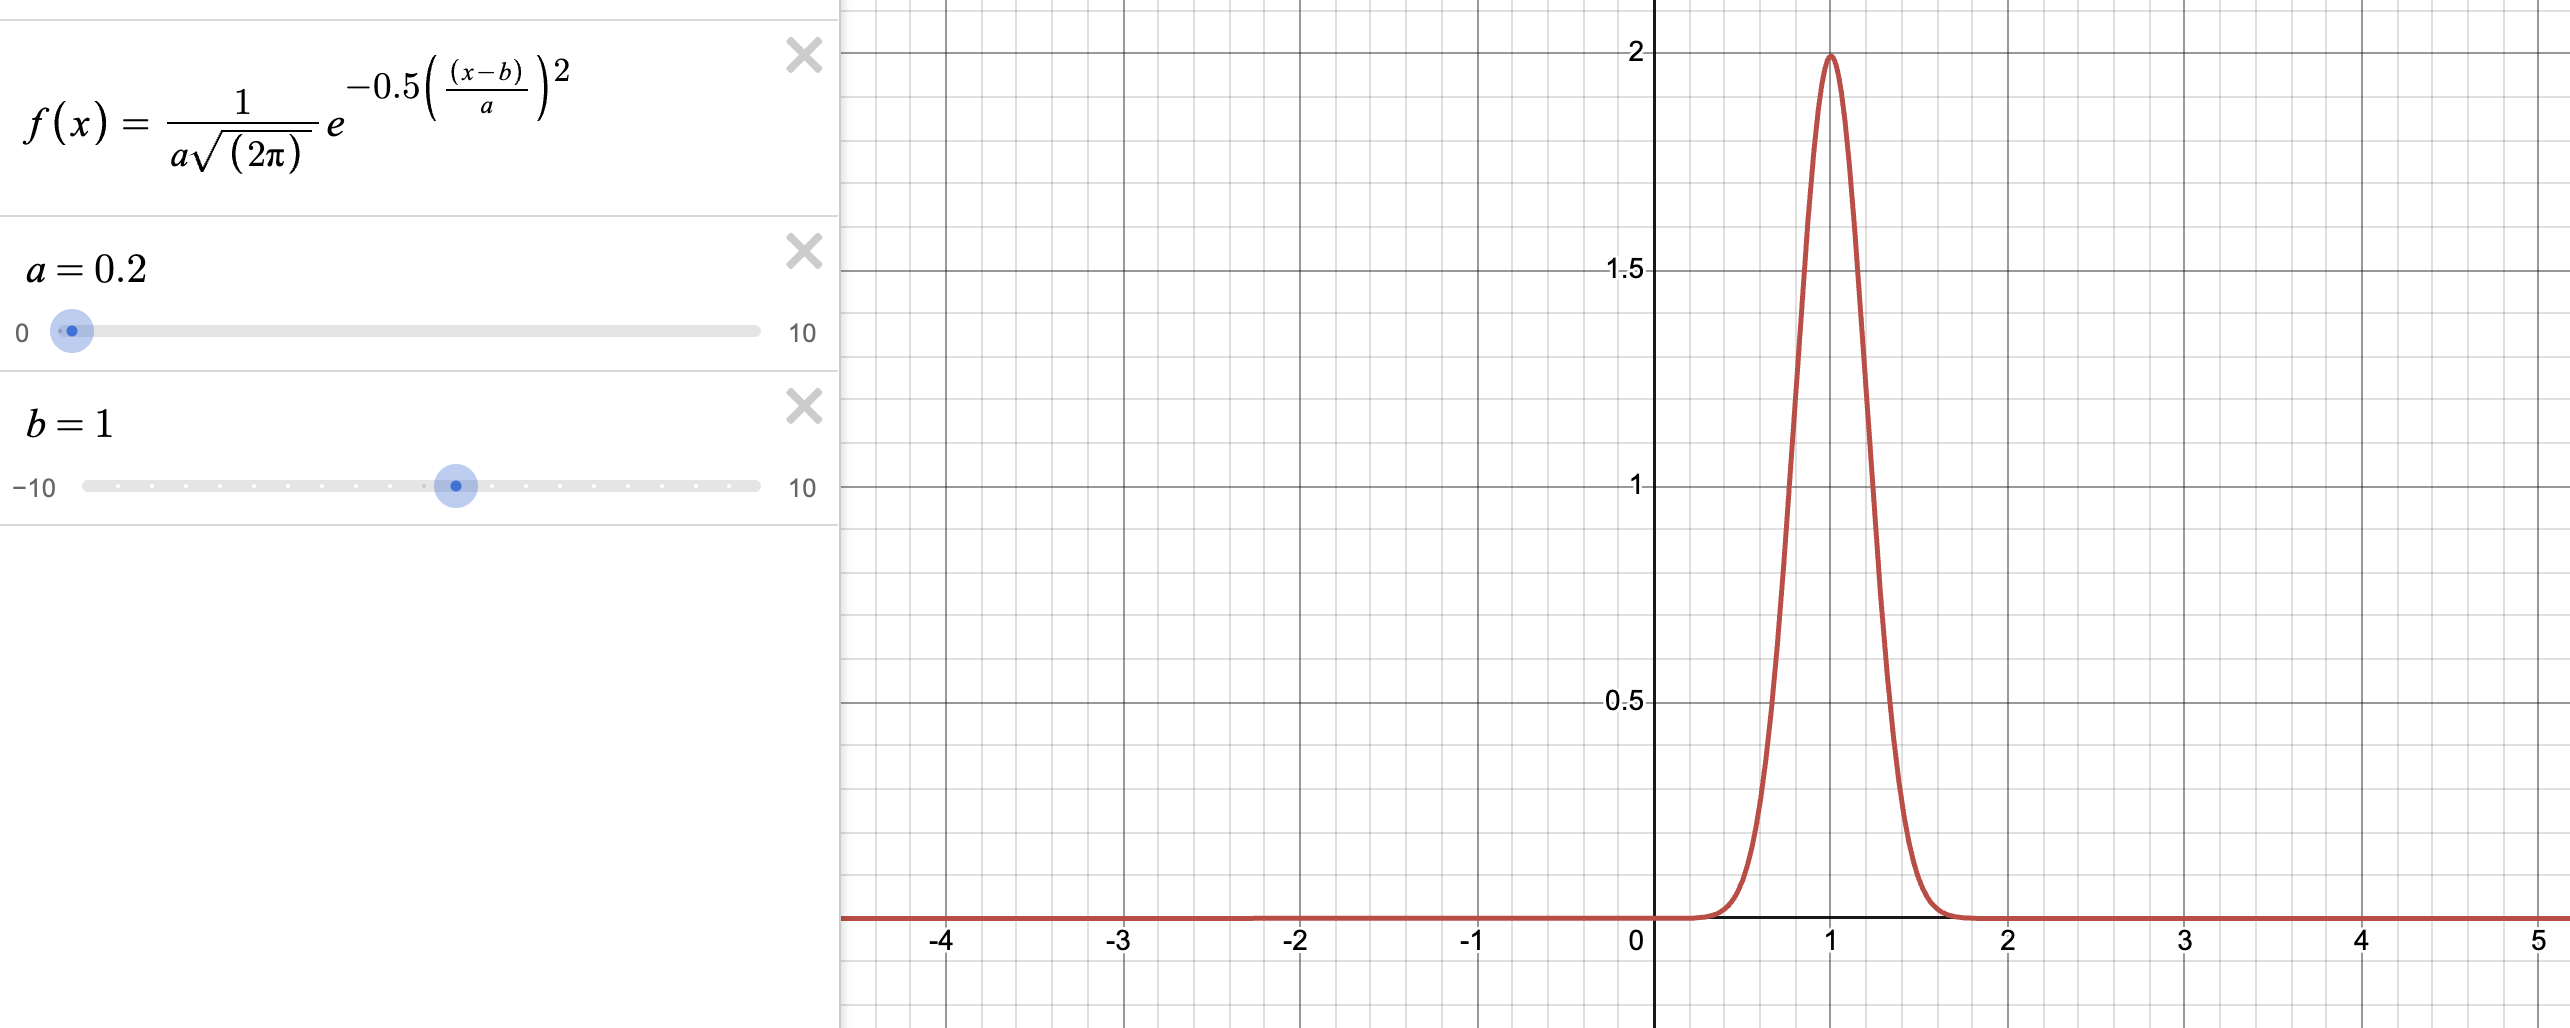

In [27]:
import torch
import re

def create_V_matrix(predicates):
    # Extract all variable names
    variable_set = set()
    predicate_vars = []
    for pred in predicates:
        # Extract variables inside parentheses
        vars_in_pred = re.findall(r'\((.*?)\)', pred)
        if vars_in_pred:
            vars_list = [v.strip() for v in vars_in_pred[0].split(',')]
        else:
            vars_list = []
        predicate_vars.append(vars_list)
        variable_set.update(vars_list)
    # Sort variables for consistent column order
    variables = sorted(variable_set, key=lambda x: (int(x[1:]) if x[1:].isdigit() else x))
    var_idx = {v: i for i, v in enumerate(variables)}
    # Build the matrix
    V = torch.zeros((len(predicates), len(variables)), dtype=torch.float32)
    for i, vars_list in enumerate(predicate_vars):
        for v in vars_list:
            V[i, var_idx[v]] = 1.0
    return V, variables

V_matrix:
 tensor([[1., 1., 0.],
        [1., 0., 0.],
        [0., 1., 1.],
        [1., 0., 1.]])
Variable order: ['X1', 'X2', 'X3']
Restart 1/5 Final Loss: 0.6484
Restart 2/5 Final Loss: 0.6480
Restart 3/5 Final Loss: 0.6481
Restart 4/5 Final Loss: 0.6483
Restart 5/5 Final Loss: 0.6482


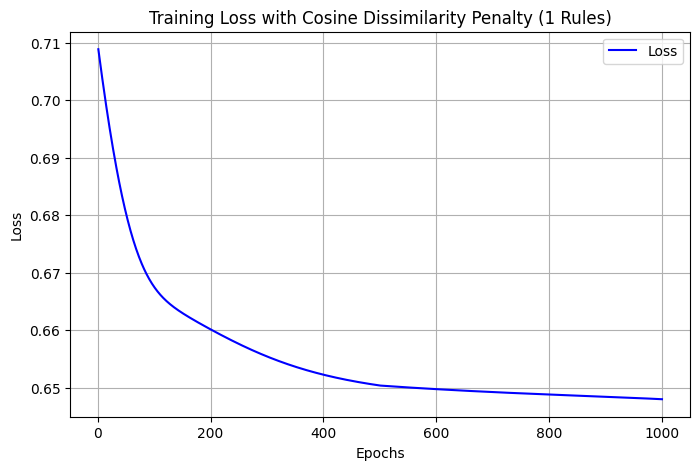

The most repeated rule is: 'h1 :- not(b2) and b3.'
It appears 356 times out of 500.

Final Rule:
h :- not(b2) and b3.

Final M matrices:
M1: [1.1313952207565308, 1.4154682159423828, 1.067812204360962]


In [ ]:
# Re-execution after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter

# Define predicate-variable binary matrix
V_matrix = torch.tensor([
    [1, 1, 0],  # b1(X1, X2)
    [1, 0, 0],  # b2(X1)
    [0, 1, 1],  # b3(X2, X3)
    [1, 0, 1],  # b4(X1, X3)
], dtype=torch.float32)

# Define CustomNeuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)

    def forward(self, x):
        #self.weights = torch.softmax(self.raw_weights, dim=0)
        self.weights = torch.sigmoid(self.raw_weights)  # Ensure weights are in [0, 1]
        self.weights = self.weights / self.weights.sum()  # Normalize weights to sum to 1
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

# Define FuzzyDisjunctionNet
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            P = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])  # 1 - w3

            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)

            P_tensor = torch.stack(P)
            M = torch.matmul(P_tensor, self.V)
            self.M_matrices.append(M)

            rule_output = torch.exp(sum(conjunctions))
            rule_outputs.append(rule_output)

        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r

        return fuzzy_or

# Parameters
num_rules = 1
num_neurons_per_rule = 4
input_dim = 4
num_samples = 500
num_epochs = 1000
num_restarts = 5
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
# put the second column same as the first column
X_train[:, 1] = X_train[:, 0]
y_train = ((1 - X_train[:, 0]) * X_train[:, 2] > 0.25).float()

# Body predicates and their variables
# B = {b1(X1, X2), b2(X1), b3(X2, X3), b4(X1, X3)}
predicates = ["b1(X1, X2)", "b2(X1)", "b3(X2, X3)", "b4(X1, X3)"]
V_matrix, variable_order = create_V_matrix(predicates)
print("V_matrix:\n", V_matrix)
print("Variable order:", variable_order)

# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Compute range resticted loss -> the probability of the head variables being present in the rule
        M = model_nsre.M_matrices
        # Find the corresponding values of M to head variables (here Variable 1 and 3)
        head_vars = [0, 2]
        M_head = [M[i][head_vars] for i in range(num_rules)]
        # Multiply the elements of M_head
        head_var_probs = torch.prod(torch.stack(M_head), dim=0)
        # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
        range_restricted_loss = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))
        # print(f"Range Restricted Loss: {range_restricted_loss.item()}")

        # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
        # The only auxiliary variable is X2
        connected_vars = [1]
        M_connected = [M[i][connected_vars] for i in range(num_rules)]

        # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
        import math
        Sum_Fx = 0.0
        for i, M in enumerate(M_connected):
            mean = 1.0
            std = 0.2
            Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
        connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules

        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term + 0.1 * range_restricted_loss #+ 0.1 * connected_loss
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load best model and compute M
best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
best_model.load_state_dict(best_state_dict)
_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {M}")

## Ablation Study

In [4]:
def compute_acc_ratio_all_rules_attention(model, x, y, beta=10.0):
    with torch.no_grad():
        rule_outputs = []
        for rule in model.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % model.input_dim]]
                conjunctions.append(neuron(xi).squeeze())
            # Softmin attention over neurons (optional, or just use sum)
            conjunctions = torch.stack(conjunctions, dim=1)  # (batch, num_neurons)
            attention_weights = torch.softmax(-beta * conjunctions, dim=1)
            outputs = (attention_weights * conjunctions).sum(dim=1)  # (batch,)
            activated_outputs = torch.sigmoid(5 * (outputs - 0.5))
            rule_outputs.append(activated_outputs)

        # Stack rule outputs: shape (num_rules, batch)
        rule_outputs_tensor = torch.stack(rule_outputs, dim=0)  # (num_rules, batch)
        # Softmax attention over rules for each sample (dim=0)
        attention_weights = torch.softmax(beta * rule_outputs_tensor, dim=0)
        # Weighted sum over rules for each sample
        final_output = (attention_weights * rule_outputs_tensor).sum(dim=0)  # (batch,)
        # Compute accuracy
        preds = (final_output > 0.5).float()
        acc = (preds == (y > 0.5)).float().mean().item()
        return acc

## ANDRE with Attention-based Conjunction-Disjunction Operators

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 10.0  # Example value for beta
LAMBDA = 5.0  # Example value for lambda
GAMMA = 0.5  # Example value for gamma
# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

class ANDRE(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(ANDRE, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(LAMBDA*(sum(outputs) - GAMMA))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(LAMBDA*(sum(rule_outputs) - GAMMA))  # Apply sigmoid to the sum

        return activated_output

Num Rules: 4, Restart 1/1, Final Loss: 0.2588.
Overall accuracy ratio: 0.9330
Num Rules: 4, Restart 1/1, Final Loss: 0.2359.
Overall accuracy ratio: 0.9440
Num Rules: 4, Restart 1/1, Final Loss: 0.2318.
Overall accuracy ratio: 0.9460
Num Rules: 4, Restart 1/1, Final Loss: 0.2422.
Overall accuracy ratio: 0.9410
Num Rules: 4, Restart 1/1, Final Loss: 0.2235.
Overall accuracy ratio: 0.9500
Num Rules: 4, Restart 1/1, Final Loss: 0.2692.
Overall accuracy ratio: 0.9280
Num Rules: 4, Restart 1/1, Final Loss: 0.2464.
Overall accuracy ratio: 0.9390
Num Rules: 4, Restart 1/1, Final Loss: 0.2276.
Overall accuracy ratio: 0.9480
Num Rules: 4, Restart 1/1, Final Loss: 0.2318.
Overall accuracy ratio: 0.9460
Num Rules: 4, Restart 1/1, Final Loss: 0.2547.
Overall accuracy ratio: 0.9350
Num Rules: 4, Restart 1/1, Final Loss: 0.2380.
Overall accuracy ratio: 0.9430
Num Rules: 4, Restart 1/1, Final Loss: 0.2505.
Overall accuracy ratio: 0.9370
Num Rules: 4, Restart 1/1, Final Loss: 0.2505.
Overall accuracy 

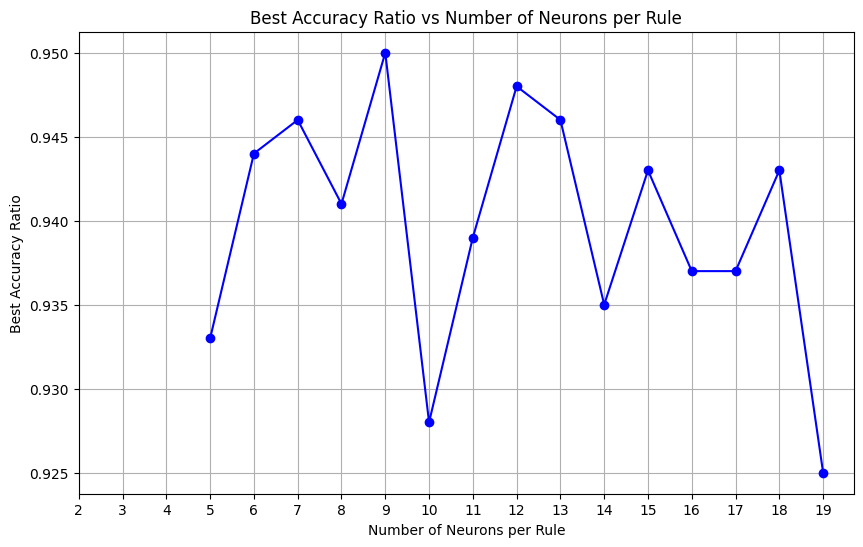

In [ ]:
from collections import Counter
import time
start_time = time.time()
# Parameters
num_rules = 4
num_samples = 1000
num_epochs = 1000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

best_acc_ratios_andre = []

for k in range(num_rules + 1, 20):
    num_neurons_per_rule = k
    input_dim = num_neurons_per_rule
    num_rules = 4
    # Initialize history for weights: [rule][neuron][epoch][weight]
    weights_history = [
        [ [] for _ in range(num_neurons_per_rule) ]
        for _ in range(num_rules)
    ]
    # Multi-Restart Training
    best_state_dict = None
    best_loss = float('inf')
    best_losses = []
    # Probability input data
    X_train = torch.rand(num_samples, input_dim)  # Random probabilities
    # y_train = (((1 - X_train[:, 1]) > 0.5) & (X_train[:, 0] > 0.5)).float()
    y_train = ((X_train[:, 0] > 0.5) | (X_train[:, 1] > 0.5) | (X_train[:, 2] > 0.5) | (X_train[:, 3] > 0.5)).float()

    best_acc_ratio = 0.0
    for restart in range(num_restarts):
        model_nsre = ANDRE(num_rules, num_neurons_per_rule, input_dim)
        # criterion = nn.BCEWithLogitsLoss()
        criterion = nn.BCELoss()  # Use BCELoss for sigmoid outputs
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            # Cosine similarity loss
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Entropy regularization for exploration
            entropy_term = sum(model_nsre.entropies)

            # total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term #+ 0.1*sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term + 0.1 * sum_weights_loss
            total_loss = bce_loss #- entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            # best_num_rules = num_rules + 1  # Store the best number of rules
            # print(f"New best model found with {best_num_rules} rules and loss: {best_loss:.4f}")

        # Compute acc_ratio on training data
        # for r in range(len(model_nsre.rules)):
        #     acc_ratio = compute_acc_ratio(model_nsre, X_train, y_train, r)
        #     print(f"Rule {r + 1} accuracy ratio: {acc_ratio:.4f}")
        acc_ratio_all = compute_acc_ratio_all_rules_attention(model_nsre, X_train, y_train)
        if acc_ratio_all > best_acc_ratio:
            best_acc_ratio = acc_ratio_all
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_num_rules = num_rules + 1

        print(f"Overall accuracy ratio: {acc_ratio_all:.4f}")
    best_acc_ratios_andre.append(best_acc_ratio)

# Load the best model
# best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
# best_model.load_state_dict(best_state_dict)

# Plot accuracy ratios with respect to number of neurons per rule
plt.figure(figsize=(10, 6))
plt.plot(range(num_rules + 1, 20), best_acc_ratios_andre, marker='o', linestyle='-', color='blue')
plt.xlabel("Number of Neurons per Rule")
plt.ylabel("Best Accuracy Ratio")
plt.title("Best Accuracy Ratio vs Number of Neurons per Rule")
plt.xticks(range(num_rules + 1, 20))
plt.grid(True)
# plt.savefig('best_accuracy_ratio_vs_neurons.pdf', bbox_inches='tight')
plt.show()

# Plot loss curve
# plt.figure(figsize=(8, 5))
# plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
# plt.xlabel("Epochs")
# plt.ylabel("Loss")
# plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
# plt.legend()
# plt.grid(True)
# plt.show()

# # Plot weights for each neuron in each rule
# fig, axes = plt.subplots(num_rules, num_neurons_per_rule, figsize=(5 * num_neurons_per_rule, 4 * num_rules), sharey=True)
# if num_rules == 1:
#     axes = [axes]
# for rule_idx in range(num_rules):
#     for neuron_idx in range(num_neurons_per_rule):
#         ax = axes[rule_idx][neuron_idx] if num_rules > 1 else axes[neuron_idx]
#         weights_arr = np.array(weights_history[rule_idx][neuron_idx])  # shape: (epochs, 3)
#         for w_idx in range(weights_arr.shape[1]):
#             label = f'$w_{w_idx+1}^{{{rule_idx+1}{neuron_idx+1}}}$'
#             ax.plot(weights_arr[:, w_idx], label=label)
#         ax.set_title(f'Rule {rule_idx+1} Neuron {neuron_idx+1}')
#         ax.set_xlabel('Epoch')
#         ax.set_ylabel('Weight Value')
#         ax.legend()
#         ax.grid(True)
# plt.tight_layout()
# plt.show()

# # Save final weights for inspection
# Weights_nsre = []
# for rule in best_model.rules:
#     rule_weights = []
#     for neuron in rule:
#         weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
#         rule_weights.append(weights)
#     Weights_nsre.append(rule_weights)

# print("\nFinal Weights of the Network:")
# for rule_num, rule_weights in enumerate(Weights_nsre):
#     print(f"Rule {rule_num+1}:")
#     for i, weights in enumerate(rule_weights):
#         print(f"  Neuron {i+1}: {weights}") 

# # Rule interpretation
# Predicate_values = X_train
# input_dim = 4

# Final_rules = []
# for rule_num, weights in enumerate(Weights_nsre):
#     Extracted_rules = []
#     for i in range(len(Predicate_values)):
#         pred_values = Predicate_values[i].numpy()
#         preds = interpret_neuron_weights_(pred_values, weights)
#         refined_preds = [pred for pred in preds if pred != '1']
#         rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
#         Extracted_rules.append(rule)

#     rule_counts = Counter(Extracted_rules)
#     most_common_rule, count = rule_counts.most_common(1)[0]
#     print(f"The most repeated rule is: '{most_common_rule}'")
#     print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

#     Final_rules.append(most_common_rule)

# # remove the "h{i+1} :- " part from each rule
# Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# # remove the "."
# Final_rules = [rule.replace(".", "") for rule in Final_rules]

# # convert the rules to a single rule
# final_rule = "h :- " + " OR ".join(Final_rules) + "."
# print("\n======================================")
# print("Final Rule:")
# print(final_rule)
# print("======================================")

# end_time = time.time()
# execution_time = end_time - start_time
# print(f"Execution time: {execution_time:.2f} seconds")


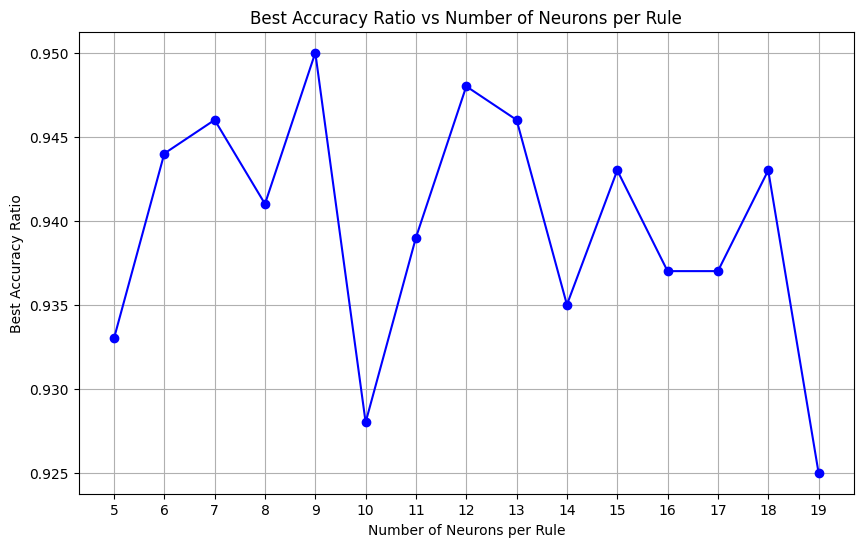

In [31]:
plt.figure(figsize=(10, 6))
plt.plot(range(num_rules + 1, 20), best_acc_ratios_andre, marker='o', linestyle='-', color='blue')
plt.xlabel("Number of Neurons per Rule")
plt.ylabel("Best Accuracy Ratio")
plt.title("Best Accuracy Ratio vs Number of Neurons per Rule")
plt.xticks(range(num_rules + 1, 20))
plt.grid(True)
# plt.savefig('best_accuracy_ratio_vs_neurons.pdf', bbox_inches='tight')
plt.show()

## ANDRE with Product-based Conjunction-Disjunction Operators

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron_(nn.Module):
    def __init__(self):
        super(CustomNeuron_, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(activated_input)

class ANDRE2(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(ANDRE2, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron_() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            Sum_third_weights = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                with torch.no_grad():
                    Sum_third_weights += weights[2]
            Sum_third_weights = Sum_third_weights.detach()
            Sum_third_weights = max(Sum_third_weights, 1)
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            rule_output = torch.exp(sum(conjunctions))
            activated_rule_output = torch.sigmoid(5 * (rule_output - 0.5))
            rule_outputs.append(activated_rule_output)

        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r
        fuzzy_or = torch.sigmoid(5 * (fuzzy_or - 0.5))
        return fuzzy_or

Num Rules: 1, Restart 1/3, Final Loss: 0.3294.
Overall accuracy ratio: 0.6950
Num Rules: 1, Restart 2/3, Final Loss: 0.3295.
Overall accuracy ratio: 0.6950
Num Rules: 1, Restart 3/3, Final Loss: 0.3296.
Overall accuracy ratio: 0.6950
Num Rules: 1, Restart 1/3, Final Loss: 0.3224.
Overall accuracy ratio: 0.7050
Num Rules: 1, Restart 2/3, Final Loss: 0.3224.
Overall accuracy ratio: 0.7050
Num Rules: 1, Restart 3/3, Final Loss: 0.3225.
Overall accuracy ratio: 0.7050
Num Rules: 1, Restart 1/3, Final Loss: 0.2869.
Overall accuracy ratio: 0.7850
Num Rules: 1, Restart 2/3, Final Loss: 0.2869.
Overall accuracy ratio: 0.7850
Num Rules: 1, Restart 3/3, Final Loss: 0.2869.
Overall accuracy ratio: 0.7850
Num Rules: 1, Restart 1/3, Final Loss: 0.3043.
Overall accuracy ratio: 0.7950
Num Rules: 1, Restart 2/3, Final Loss: 0.3043.
Overall accuracy ratio: 0.7950
Num Rules: 1, Restart 3/3, Final Loss: 0.3043.
Overall accuracy ratio: 0.7950
Num Rules: 1, Restart 1/3, Final Loss: 0.2786.
Overall accuracy 

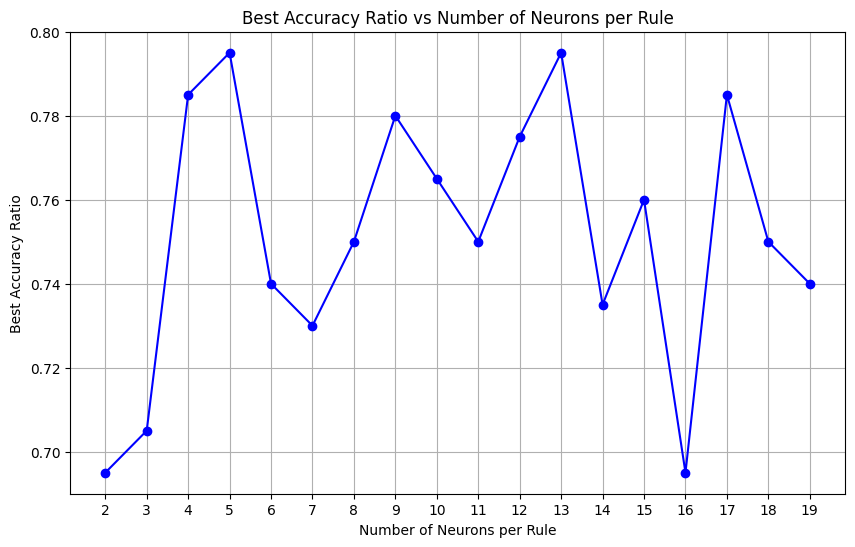

In [16]:
from collections import Counter
import time
start_time = time.time()
# Parameters
num_rules = 1
num_samples = 200
num_epochs = 1000
num_restarts = 3
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

best_acc_ratios_andre2 = []

for k in range(2, 20):
    num_neurons_per_rule = k
    input_dim = num_neurons_per_rule
    num_rules = 1
    # Initialize history for weights: [rule][neuron][epoch][weight]
    weights_history = [
        [ [] for _ in range(num_neurons_per_rule) ]
        for _ in range(num_rules)
    ]
    # Multi-Restart Training
    best_state_dict = None
    best_loss = float('inf')
    best_losses = []
    # Probability input data
    X_train = torch.rand(num_samples, input_dim)  # Random probabilities
    y_train = (((1 - X_train[:, 1]) > 0.5) & (X_train[:, 0] > 0.5)).float()

    best_acc_ratio = 0.0
    for restart in range(num_restarts):
        model_nsre = ANDRE2(num_rules, num_neurons_per_rule, input_dim)
        # criterion = nn.BCEWithLogitsLoss()
        criterion = nn.BCELoss()  # Use BCELoss for sigmoid outputs
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            # Cosine similarity loss
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Entropy regularization for exploration
            entropy_term = sum(model_nsre.entropies)

            # total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term #+ 0.1*sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term + 0.1 * sum_weights_loss
            total_loss = bce_loss #- entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            # best_num_rules = num_rules + 1  # Store the best number of rules
            # print(f"New best model found with {best_num_rules} rules and loss: {best_loss:.4f}")

        # Compute acc_ratio on training data
        # for r in range(len(model_nsre.rules)):
        #     acc_ratio = compute_acc_ratio(model_nsre, X_train, y_train, r)
        #     print(f"Rule {r + 1} accuracy ratio: {acc_ratio:.4f}")
        acc_ratio_all = compute_acc_ratio_all_rules_attention(model_nsre, X_train, y_train)
        if acc_ratio_all > best_acc_ratio:
            best_acc_ratio = acc_ratio_all
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_num_rules = num_rules + 1

        print(f"Overall accuracy ratio: {acc_ratio_all:.4f}")
    best_acc_ratios_andre2.append(best_acc_ratio)

# Load the best model
# best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
# best_model.load_state_dict(best_state_dict)

# Plot accuracy ratios with respect to number of neurons per rule
plt.figure(figsize=(10, 6))
plt.plot(range(2, 20), best_acc_ratios_andre2, marker='o', linestyle='-', color='blue')
plt.xlabel("Number of Neurons per Rule")
plt.ylabel("Best Accuracy Ratio")
plt.title("Best Accuracy Ratio vs Number of Neurons per Rule")
plt.xticks(range(2, 20))
plt.grid(True)
# plt.savefig('best_accuracy_ratio_vs_neurons.pdf', bbox_inches='tight')
plt.show()

# Plot loss curve
# plt.figure(figsize=(8, 5))
# plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
# plt.xlabel("Epochs")
# plt.ylabel("Loss")
# plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
# plt.legend()
# plt.grid(True)
# plt.show()

# # Plot weights for each neuron in each rule
# fig, axes = plt.subplots(num_rules, num_neurons_per_rule, figsize=(5 * num_neurons_per_rule, 4 * num_rules), sharey=True)
# if num_rules == 1:
#     axes = [axes]
# for rule_idx in range(num_rules):
#     for neuron_idx in range(num_neurons_per_rule):
#         ax = axes[rule_idx][neuron_idx] if num_rules > 1 else axes[neuron_idx]
#         weights_arr = np.array(weights_history[rule_idx][neuron_idx])  # shape: (epochs, 3)
#         for w_idx in range(weights_arr.shape[1]):
#             label = f'$w_{w_idx+1}^{{{rule_idx+1}{neuron_idx+1}}}$'
#             ax.plot(weights_arr[:, w_idx], label=label)
#         ax.set_title(f'Rule {rule_idx+1} Neuron {neuron_idx+1}')
#         ax.set_xlabel('Epoch')
#         ax.set_ylabel('Weight Value')
#         ax.legend()
#         ax.grid(True)
# plt.tight_layout()
# plt.show()

# # Save final weights for inspection
# Weights_nsre = []
# for rule in best_model.rules:
#     rule_weights = []
#     for neuron in rule:
#         weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
#         rule_weights.append(weights)
#     Weights_nsre.append(rule_weights)

# print("\nFinal Weights of the Network:")
# for rule_num, rule_weights in enumerate(Weights_nsre):
#     print(f"Rule {rule_num+1}:")
#     for i, weights in enumerate(rule_weights):
#         print(f"  Neuron {i+1}: {weights}") 

# # Rule interpretation
# Predicate_values = X_train
# input_dim = 4

# Final_rules = []
# for rule_num, weights in enumerate(Weights_nsre):
#     Extracted_rules = []
#     for i in range(len(Predicate_values)):
#         pred_values = Predicate_values[i].numpy()
#         preds = interpret_neuron_weights_(pred_values, weights)
#         refined_preds = [pred for pred in preds if pred != '1']
#         rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
#         Extracted_rules.append(rule)

#     rule_counts = Counter(Extracted_rules)
#     most_common_rule, count = rule_counts.most_common(1)[0]
#     print(f"The most repeated rule is: '{most_common_rule}'")
#     print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

#     Final_rules.append(most_common_rule)

# # remove the "h{i+1} :- " part from each rule
# Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# # remove the "."
# Final_rules = [rule.replace(".", "") for rule in Final_rules]

# # convert the rules to a single rule
# final_rule = "h :- " + " OR ".join(Final_rules) + "."
# print("\n======================================")
# print("Final Rule:")
# print(final_rule)
# print("======================================")

# end_time = time.time()
# execution_time = end_time - start_time
# print(f"Execution time: {execution_time:.2f} seconds")


## ANDRE with attention-based conjunction and product-based disjunction

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 10.0  # Example value for beta
LAMBDA = 5.0  # Example value for lambda
GAMMA = 0.5  # Example value for gamma
# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

class ANDRE3(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(ANDRE3, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(LAMBDA*(sum(outputs) - GAMMA))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        # attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        # rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        # activated_output = torch.sigmoid(LAMBDA*(sum(rule_outputs) - GAMMA))  # Apply sigmoid to the sum
        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r
        fuzzy_or = torch.sigmoid(LAMBDA * (fuzzy_or - GAMMA))

        return fuzzy_or

Num Rules: 1, Restart 1/3, Final Loss: 0.2890.
Overall accuracy ratio: 0.9830
Num Rules: 1, Restart 2/3, Final Loss: 0.2891.
Overall accuracy ratio: 0.9830
Num Rules: 1, Restart 3/3, Final Loss: 0.2890.
Overall accuracy ratio: 0.9830
Num Rules: 1, Restart 1/3, Final Loss: 0.2829.
Overall accuracy ratio: 0.9850
Num Rules: 1, Restart 2/3, Final Loss: 0.2830.
Overall accuracy ratio: 0.9860
Num Rules: 1, Restart 3/3, Final Loss: 0.2828.
Overall accuracy ratio: 0.9850
Num Rules: 1, Restart 1/3, Final Loss: 0.2846.
Overall accuracy ratio: 0.9760
Num Rules: 1, Restart 2/3, Final Loss: 0.2849.
Overall accuracy ratio: 0.9750
Num Rules: 1, Restart 3/3, Final Loss: 0.2847.
Overall accuracy ratio: 0.9760
Num Rules: 1, Restart 1/3, Final Loss: 0.2914.
Overall accuracy ratio: 0.9660
Num Rules: 1, Restart 2/3, Final Loss: 0.2914.
Overall accuracy ratio: 0.9660
Num Rules: 1, Restart 3/3, Final Loss: 0.2916.
Overall accuracy ratio: 0.9670
Num Rules: 1, Restart 1/3, Final Loss: 0.2794.
Overall accuracy 

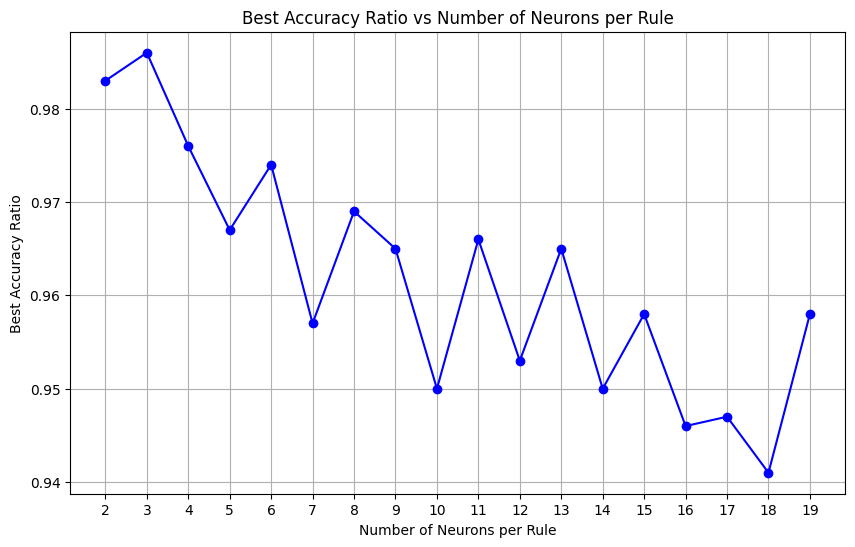

In [25]:
from collections import Counter
import time
start_time = time.time()
# Parameters
num_rules = 1
num_samples = 1000
num_epochs = 1000
num_restarts = 3
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

best_acc_ratios_andre3 = []

for k in range(2, 20):
    num_neurons_per_rule = k
    input_dim = num_neurons_per_rule
    num_rules = 1
    # Initialize history for weights: [rule][neuron][epoch][weight]
    weights_history = [
        [ [] for _ in range(num_neurons_per_rule) ]
        for _ in range(num_rules)
    ]
    # Multi-Restart Training
    best_state_dict = None
    best_loss = float('inf')
    best_losses = []
    # Probability input data
    X_train = torch.rand(num_samples, input_dim)  # Random probabilities
    y_train = (((1 - X_train[:, 1]) > 0.5) & (X_train[:, 0] > 0.5)).float()

    best_acc_ratio = 0.0
    for restart in range(num_restarts):
        model_nsre = ANDRE3(num_rules, num_neurons_per_rule, input_dim)
        # criterion = nn.BCEWithLogitsLoss()
        criterion = nn.BCELoss()  # Use BCELoss for sigmoid outputs
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            # Cosine similarity loss
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Entropy regularization for exploration
            entropy_term = sum(model_nsre.entropies)

            # total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term #+ 0.1*sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term + 0.1 * sum_weights_loss
            total_loss = bce_loss #- entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            # best_num_rules = num_rules + 1  # Store the best number of rules
            # print(f"New best model found with {best_num_rules} rules and loss: {best_loss:.4f}")

        # Compute acc_ratio on training data
        # for r in range(len(model_nsre.rules)):
        #     acc_ratio = compute_acc_ratio(model_nsre, X_train, y_train, r)
        #     print(f"Rule {r + 1} accuracy ratio: {acc_ratio:.4f}")
        acc_ratio_all = compute_acc_ratio_all_rules_attention(model_nsre, X_train, y_train)
        if acc_ratio_all > best_acc_ratio:
            best_acc_ratio = acc_ratio_all
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_num_rules = num_rules + 1

        print(f"Overall accuracy ratio: {acc_ratio_all:.4f}")
    best_acc_ratios_andre3.append(best_acc_ratio)

# Load the best model
# best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
# best_model.load_state_dict(best_state_dict)

# Plot accuracy ratios with respect to number of neurons per rule
plt.figure(figsize=(10, 6))
plt.plot(range(2, 20), best_acc_ratios_andre3, marker='o', linestyle='-', color='blue')
plt.xlabel("Number of Neurons per Rule")
plt.ylabel("Best Accuracy Ratio")
plt.title("Best Accuracy Ratio vs Number of Neurons per Rule")
plt.xticks(range(2, 20))
plt.grid(True)
# plt.savefig('best_accuracy_ratio_vs_neurons.pdf', bbox_inches='tight')
plt.show()

# Plot loss curve
# plt.figure(figsize=(8, 5))
# plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
# plt.xlabel("Epochs")
# plt.ylabel("Loss")
# plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
# plt.legend()
# plt.grid(True)
# plt.show()

# # Plot weights for each neuron in each rule
# fig, axes = plt.subplots(num_rules, num_neurons_per_rule, figsize=(5 * num_neurons_per_rule, 4 * num_rules), sharey=True)
# if num_rules == 1:
#     axes = [axes]
# for rule_idx in range(num_rules):
#     for neuron_idx in range(num_neurons_per_rule):
#         ax = axes[rule_idx][neuron_idx] if num_rules > 1 else axes[neuron_idx]
#         weights_arr = np.array(weights_history[rule_idx][neuron_idx])  # shape: (epochs, 3)
#         for w_idx in range(weights_arr.shape[1]):
#             label = f'$w_{w_idx+1}^{{{rule_idx+1}{neuron_idx+1}}}$'
#             ax.plot(weights_arr[:, w_idx], label=label)
#         ax.set_title(f'Rule {rule_idx+1} Neuron {neuron_idx+1}')
#         ax.set_xlabel('Epoch')
#         ax.set_ylabel('Weight Value')
#         ax.legend()
#         ax.grid(True)
# plt.tight_layout()
# plt.show()

# # Save final weights for inspection
# Weights_nsre = []
# for rule in best_model.rules:
#     rule_weights = []
#     for neuron in rule:
#         weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
#         rule_weights.append(weights)
#     Weights_nsre.append(rule_weights)

# print("\nFinal Weights of the Network:")
# for rule_num, rule_weights in enumerate(Weights_nsre):
#     print(f"Rule {rule_num+1}:")
#     for i, weights in enumerate(rule_weights):
#         print(f"  Neuron {i+1}: {weights}") 

# # Rule interpretation
# Predicate_values = X_train
# input_dim = 4

# Final_rules = []
# for rule_num, weights in enumerate(Weights_nsre):
#     Extracted_rules = []
#     for i in range(len(Predicate_values)):
#         pred_values = Predicate_values[i].numpy()
#         preds = interpret_neuron_weights_(pred_values, weights)
#         refined_preds = [pred for pred in preds if pred != '1']
#         rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
#         Extracted_rules.append(rule)

#     rule_counts = Counter(Extracted_rules)
#     most_common_rule, count = rule_counts.most_common(1)[0]
#     print(f"The most repeated rule is: '{most_common_rule}'")
#     print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

#     Final_rules.append(most_common_rule)

# # remove the "h{i+1} :- " part from each rule
# Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# # remove the "."
# Final_rules = [rule.replace(".", "") for rule in Final_rules]

# # convert the rules to a single rule
# final_rule = "h :- " + " OR ".join(Final_rules) + "."
# print("\n======================================")
# print("Final Rule:")
# print(final_rule)
# print("======================================")

# end_time = time.time()
# execution_time = end_time - start_time
# print(f"Execution time: {execution_time:.2f} seconds")
